In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


### Differentiaton of iAstrocytes in different conditions

In [2]:
### landing pad NGN2 differentiation
adata = sc.read('../differentiations/adatas/iAstrocytes_differentiations_counts.h5ad')
adata

AnnData object with n_obs × n_vars = 54768 × 36601
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Sample_colors'

In [3]:
adata.obs.Sample.unique()

['Krencik', 'sciencell', 'sciencell_primaryMedia', 'sciencell_amm', 'sciencell_astro3', 'Krencik_2']
Categories (6, object): ['Krencik', 'Krencik_2', 'sciencell', 'sciencell_amm', 'sciencell_astro3', 'sciencell_primaryMedia']

In [4]:
### remove genes
sc.pp.filter_genes(adata, min_cells=20)
adata.X.shape

(54768, 26503)

In [5]:
adata = adata[adata.obs.Sample!='Krencik_2']
adata

View of AnnData object with n_obs × n_vars = 51885 × 26503
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'Sample_colors'

In [6]:
adata.layers["raw"] = adata.X.copy() # preserve counts 
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()
adata.raw = adata # keep normalised log1p as raw

/tmp/ipykernel_2606824/2621682192.py:1: ImplicitModificationWarning: Setting element `.layers['raw']` of view, initializing view as actual.
  adata.layers["raw"] = adata.X.copy() # preserve counts


In [7]:
sc.pp.highly_variable_genes(
    adata,
    subset=True,
    layer="raw",
    flavor="seurat_v3",
    n_top_genes=2000,
    span=0.3,
    min_disp=0.5,
    min_mean=0.0125,
    max_mean=3,
    batch_key='Sample'
)
print(f"adata.X shape: {adata.X.shape}")
print(f"adata.raw.X shape: {adata.raw.X.shape}")

adata.X shape: (51885, 2000)
adata.raw.X shape: (51885, 26503)


In [8]:
# regress out unwanted covariates
sc.pp.regress_out(
    adata,
    keys=["n_genes_by_counts", "pct_counts_ribo", "pct_counts_mt"],
)

# scale genes to unit variance / zero mean
sc.pp.scale(adata, max_value=10)

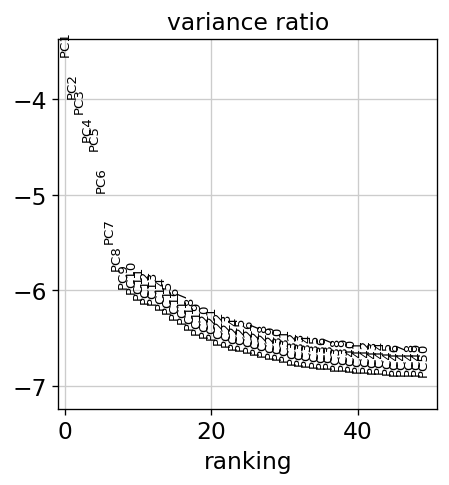

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

In [10]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

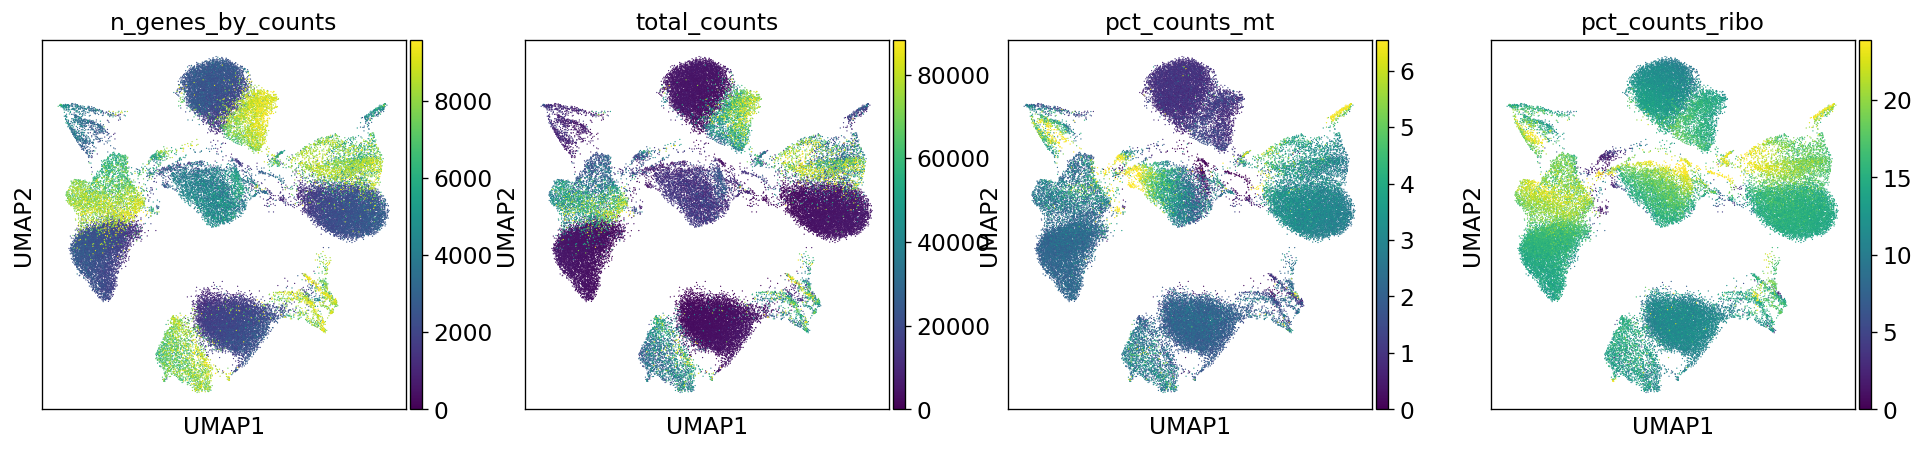

In [11]:
sc.pl.umap(adata, color=["n_genes_by_counts", "total_counts", "pct_counts_mt","pct_counts_ribo"], vmin=0, vmax='p99')

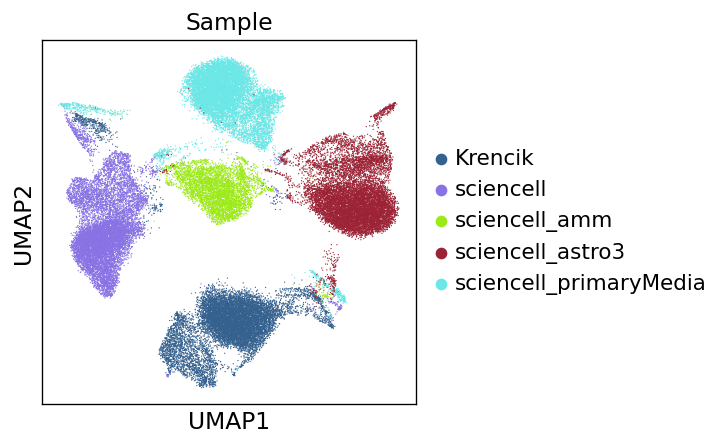

In [12]:
sc.pl.umap(adata, color=["Sample"], palette=["#35618f", "#8872e4", "#9dea19", "#9c2335", "#6ae7e6"], #"#bbcf7a",
           save='_iAstrocytes_NFIA_SOX9_differentiation_protocols_sample.pdf'
          )

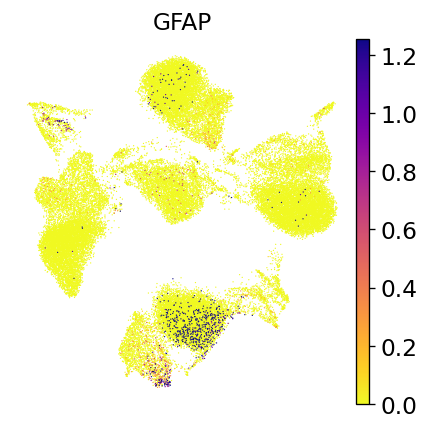

In [13]:
markers = ['GFAP'
          ]
sc.pl.umap(adata, color=[g for g in markers if g in adata.raw.var_names], vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,use_raw=True,
           save='_iAstrocytes_NFIA_SOX9_differentiation_protocols_GFAP.pdf'
          )

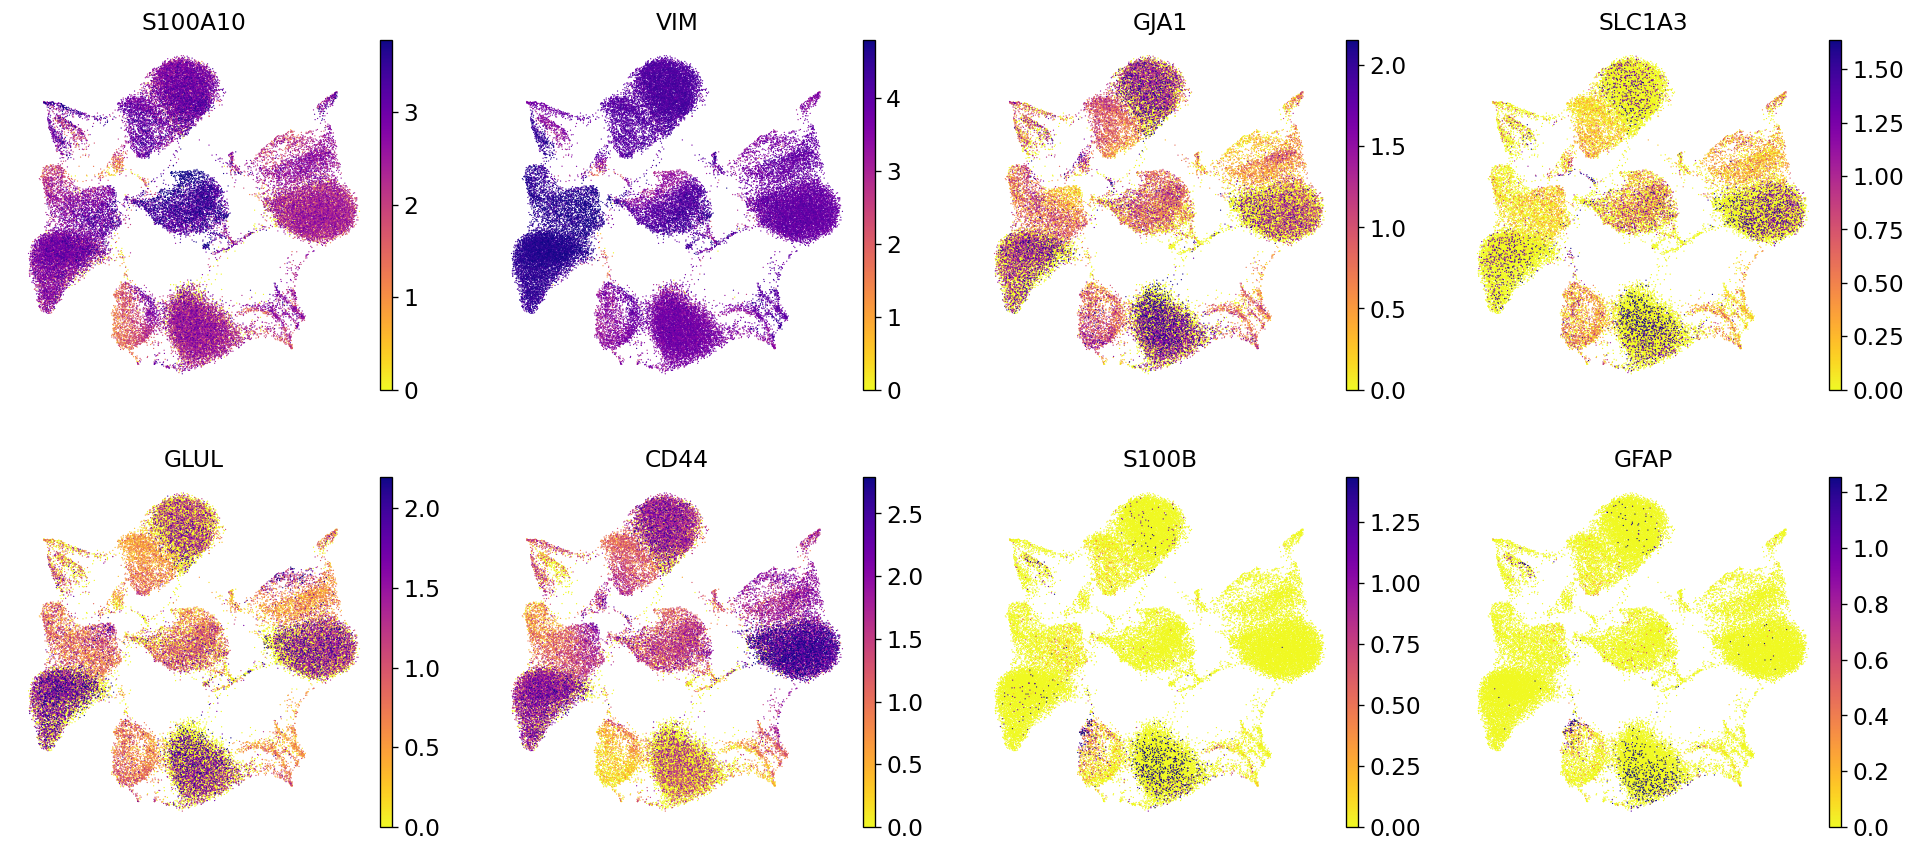

In [13]:
markers = ['S100A10',"VIM","GJA1","SLC1A3",'GLUL','CD44',"S100B","GFAP",#"APOE",'CLU'
          ]
sc.pl.umap(adata, color=[g for g in markers if g in adata.raw.var_names], vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,use_raw=True,
           save='_iAstrocytes_NFIA_SOX9_differentiation_protocols_markers.pdf'
          )

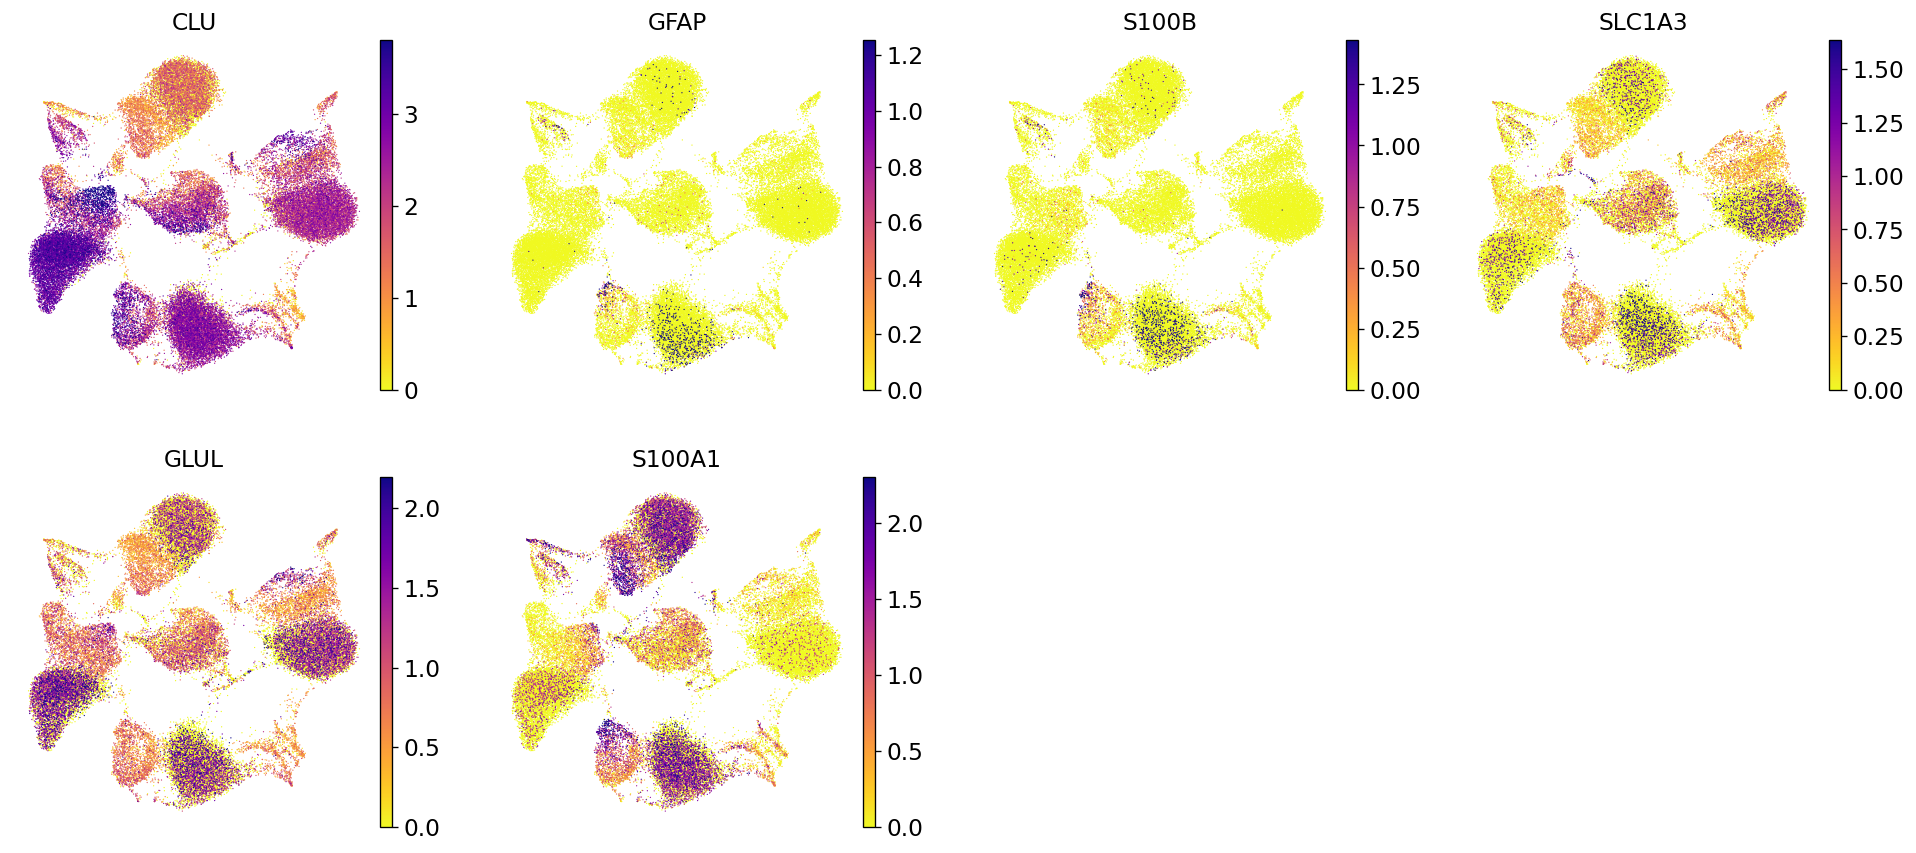

In [14]:
markers = ['CLU',"GFAP",'S100B','SLC1A3','GLUL','S100A1',#"APOE",'CLU'
          ]
sc.pl.umap(adata, color=[g for g in markers if g in adata.raw.var_names], vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,use_raw=True,
           save='_iAstrocytes_NFIA_SOX9_differentiation_protocols_markers2.pdf'
          )

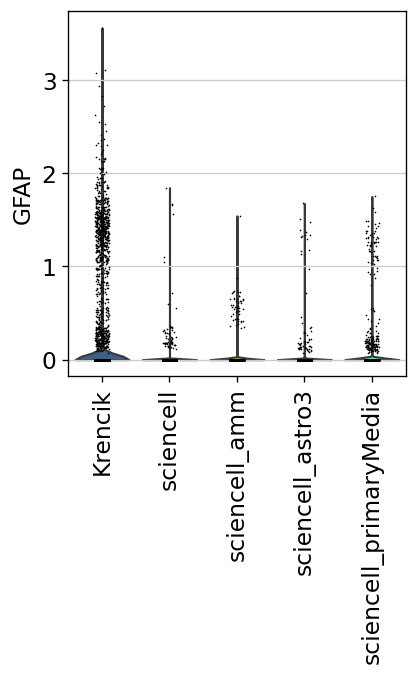

In [14]:
markers1 = ["GFAP"
          ]
markers_violin = set(markers+markers1)
for i in markers_violin:
    sc.pl.violin(adata, i, groupby = 'Sample', rotation=90, save='_iAstrocytes_NFIA_SOX9_differentiation_protocols_GFAP.pdf' )

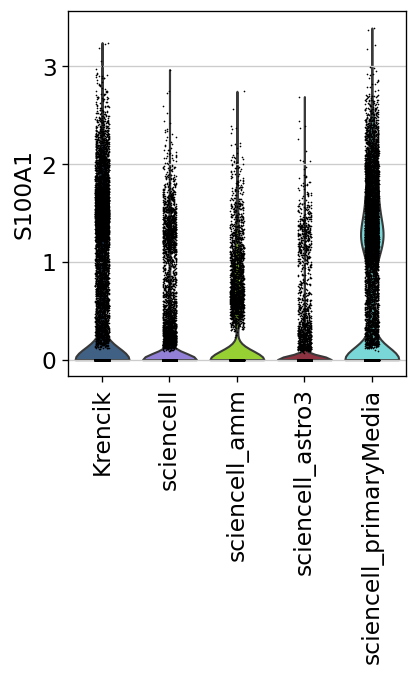

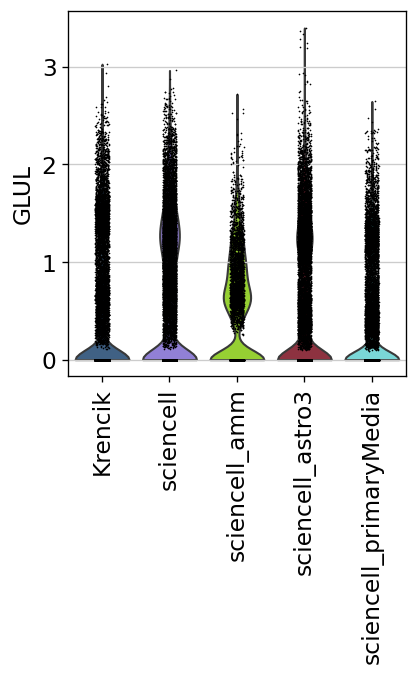

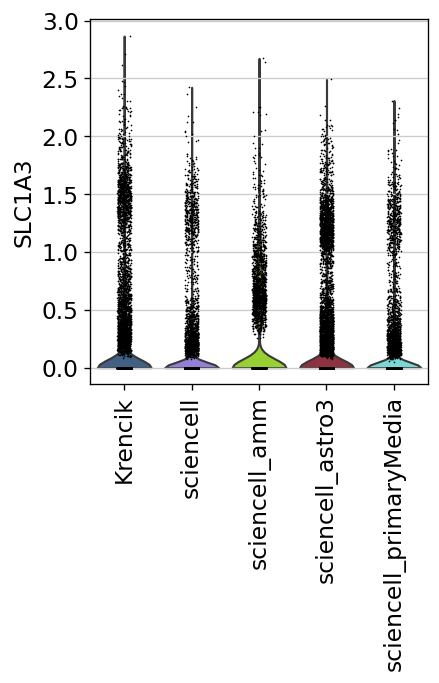

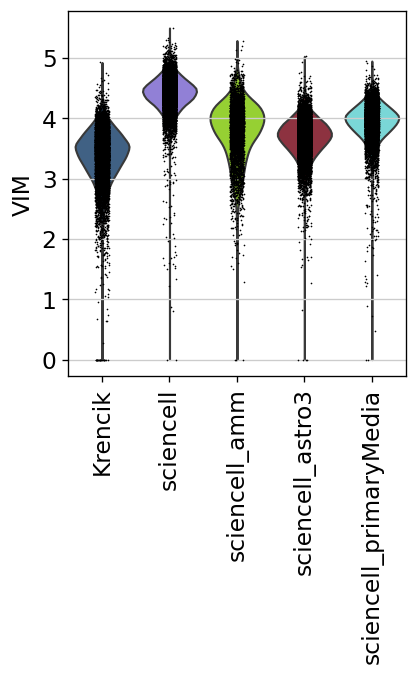

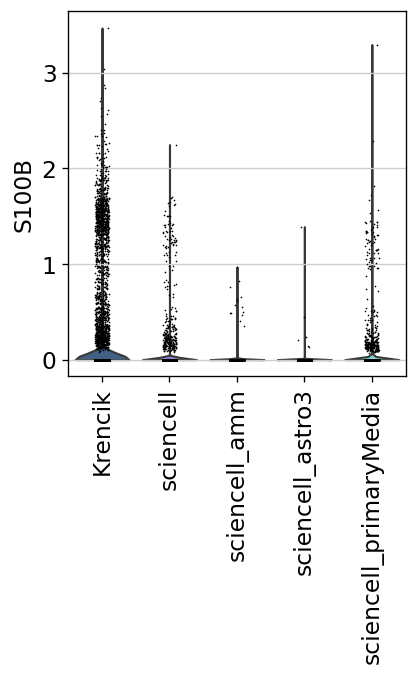

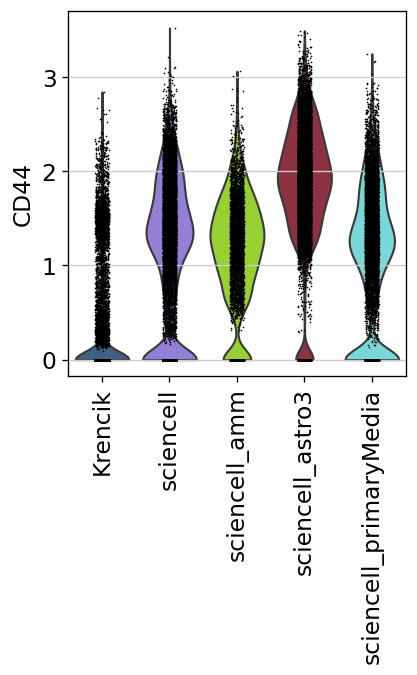

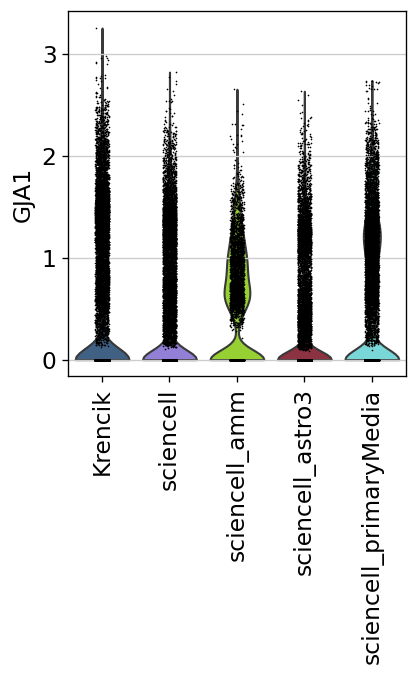

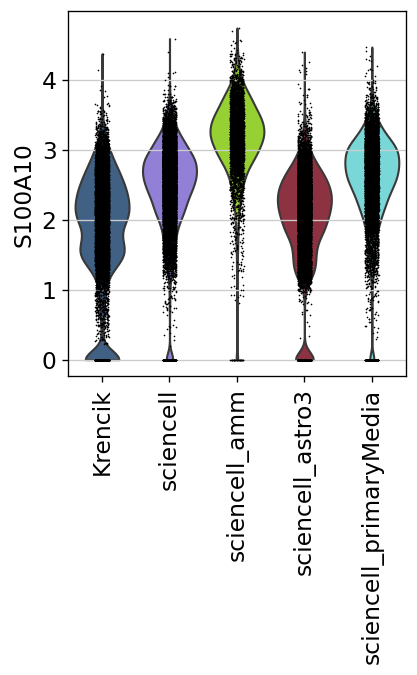

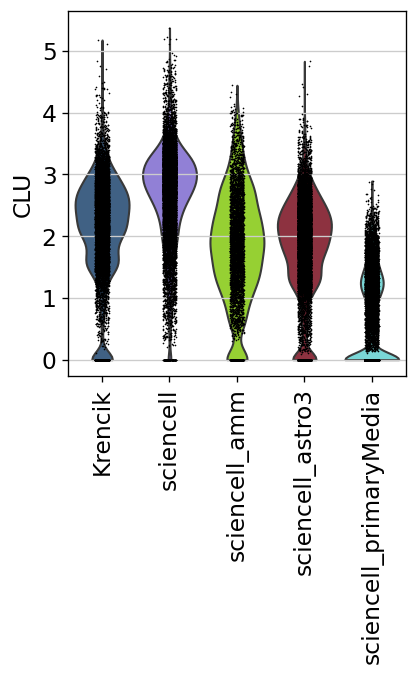

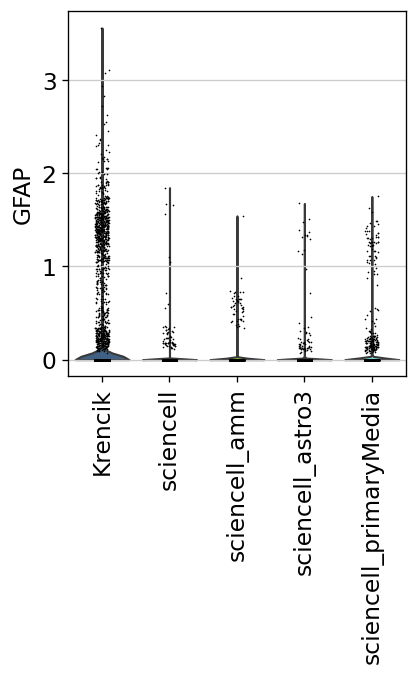

In [18]:
markers1 = ['S100A10',"VIM","GJA1","SLC1A3",'GLUL','CD44',"S100B","GFAP",#"APOE",'CLU'
          ]
markers_violin = set(markers+markers1)
for i in markers_violin:
    sc.pl.violin(adata, i, groupby = 'Sample', rotation=90 )

### cytokine induction

In [2]:
### ITC treatment DEGs from https://pmc.ncbi.nlm.nih.gov/articles/PMC11312292/
url = "https://static-content.springer.com/esm/art%3A10.1186%2Fs12974-024-03165-w/MediaObjects/12974_2024_3165_MOESM3_ESM.xlsx"
s1 = pd.read_excel(url)
s1

,gene,baseMean,log2FoldChange,lfcSE,pvalue,padj,Unnamed: 6,iAstrocytes treated with vehicle vs. IL1a+TNF+C1q for 24 hours
0,NFKBIA,3543.430456,3.846476,0.098156,0.000000e+00,0.000000e+00,NaN,NaN
1,SOD2,12794.411889,6.507369,0.112567,0.000000e+00,0.000000e+00,NaN,NaN
2,CXCL6,7230.228578,9.223394,0.222107,0.000000e+00,0.000000e+00,NaN,NaN
3,PAPPA,10077.242710,3.549457,0.084701,0.000000e+00,0.000000e+00,NaN,NaN
4,CYP1B1,4303.002918,3.458282,0.096282,3.085616e-284,1.055898e-280,NaN,NaN
...,...,...,...,...,...,...,...,...
14552,FAM157A,10.365431,0.000000,0.718847,1.000000e+00,1.000000e+00,NaN,NaN
14553,LOC101559451,2.652265,-0.000340,0.443809,9.985547e-01,1.000000e+00,NaN,NaN
14554,HP,11.767903,0.000000,0.539385,1.000000e+00,1.000000e+00,NaN,NaN
14555,LOC102724163,1.514414,0.000000,0.741779,1.000000e+00,1.000000e+00,NaN,NaN


In [3]:
ITC_genes = s1[(s1['log2FoldChange']>1) & (s1['padj']<0.05)]['gene'].to_list()

In [4]:
### ITC differentiations
adata = sc.read('../differentiations/adatas/iAstrocytes_differentiations_cytokines.h5ad')
adata

AnnData object with n_obs × n_vars = 13241 × 36601
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Sample_colors'

In [5]:
### remove genes
sc.pp.filter_genes(adata, min_cells=5)
adata.X.shape

(13241, 28295)

In [6]:
adata.layers["counts"] = adata.X.copy() # preserve counts 
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()
adata.raw = adata # keep normalised log1p as raw

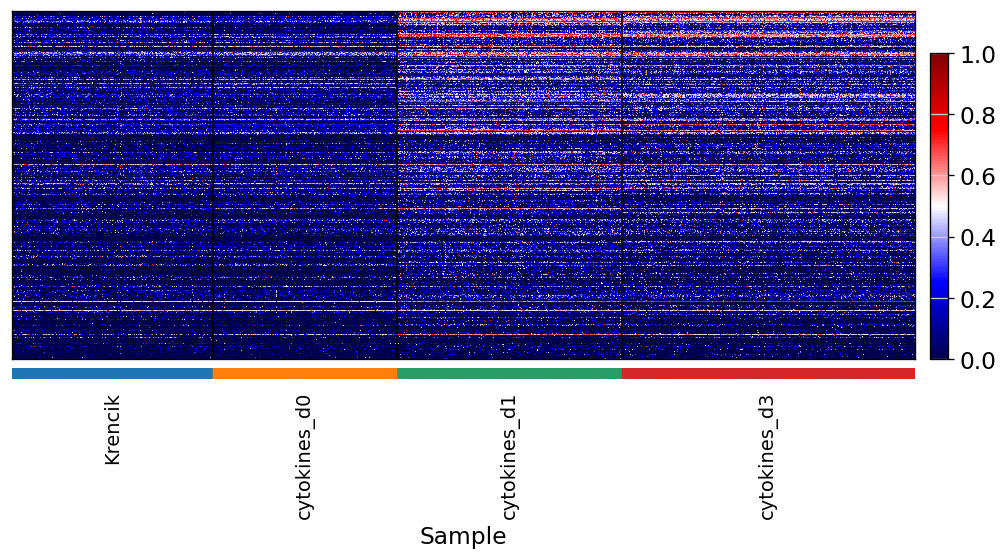

In [7]:
sc.pl.heatmap(
    adata,
    var_names=[g for g in ITC_genes if g in adata.var_names],
    groupby="Sample",   # or whatever grouping
    use_raw=True,       # or layer="log1p" if you prefer
    swap_axes=True,
    cmap="seismic",
    standard_scale="var",   # z-score per gene
    show_gene_labels=False
)

In [8]:
adata = adata[adata.obs.Sample != 'Krencik']
adata

View of AnnData object with n_obs × n_vars = 10298 × 28295
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'Sample_colors', 'log1p'
    layers: 'counts', 'log1p'

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


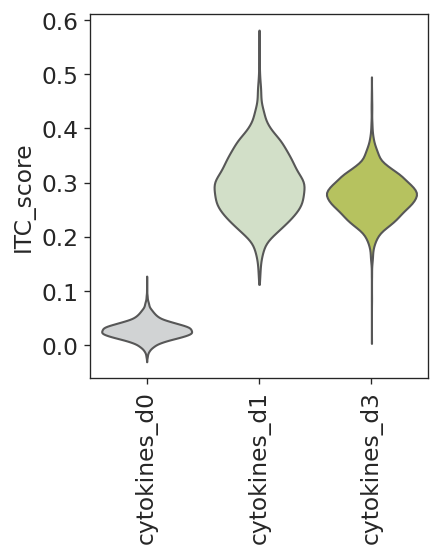

In [9]:
genes = [g for g in ITC_genes if g in adata.var_names]
sc.tl.score_genes(adata, gene_list=genes, score_name="ITC_score")
import seaborn as sns
with sns.axes_style('ticks'):
    sc.pl.violin(adata, "ITC_score", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                save='_iAstrocytes_ITC.pdf')

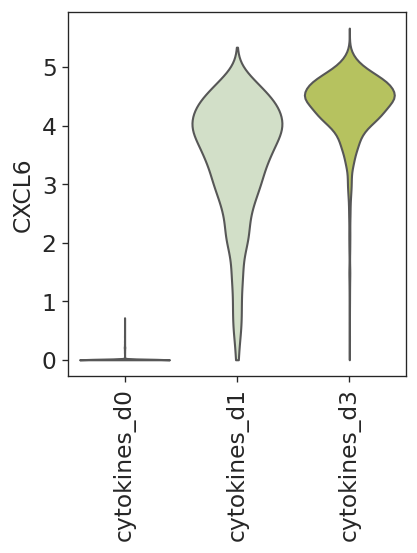

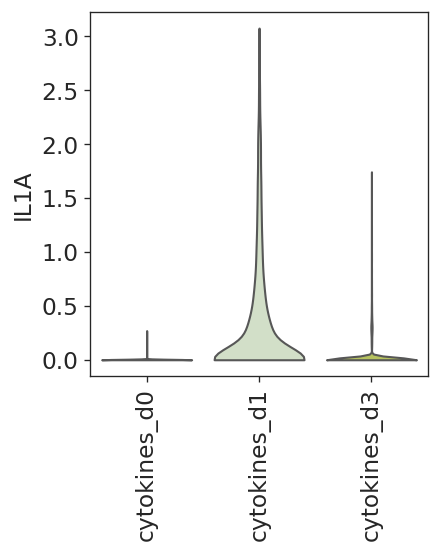

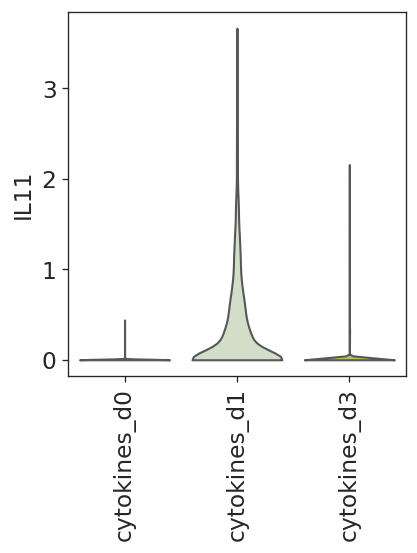

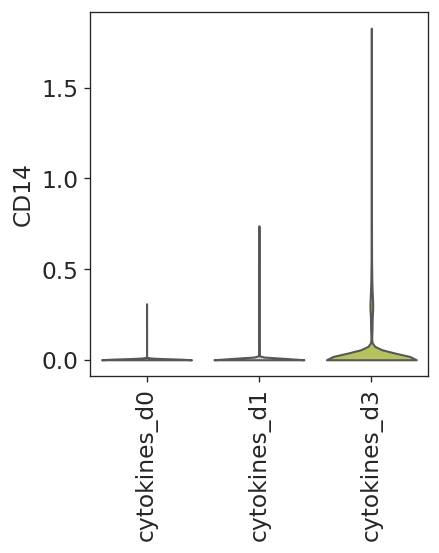

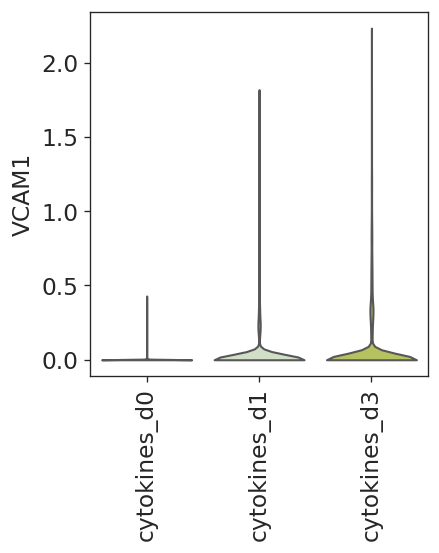

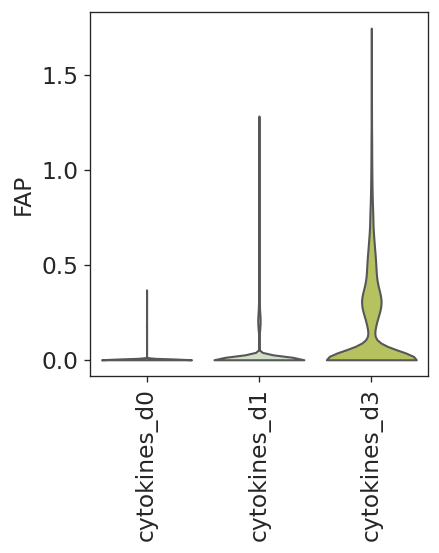

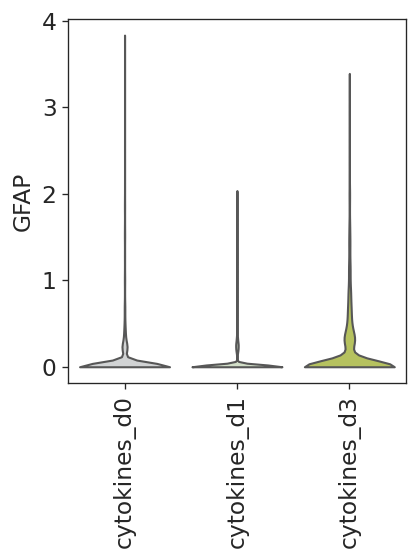

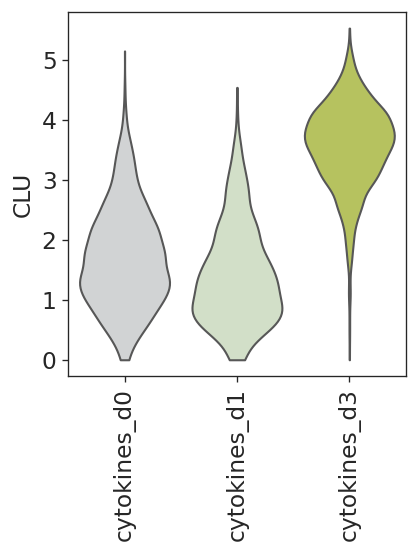

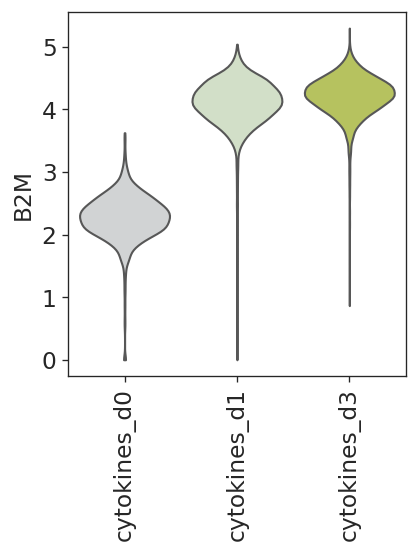

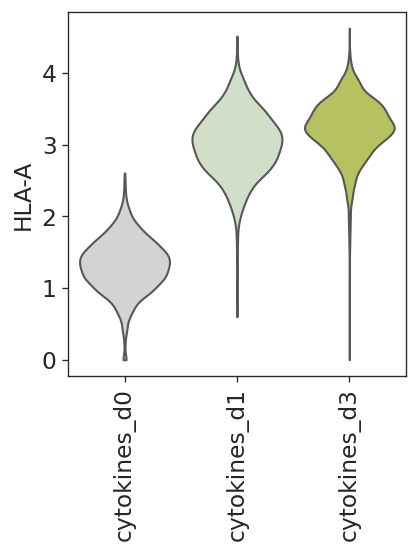

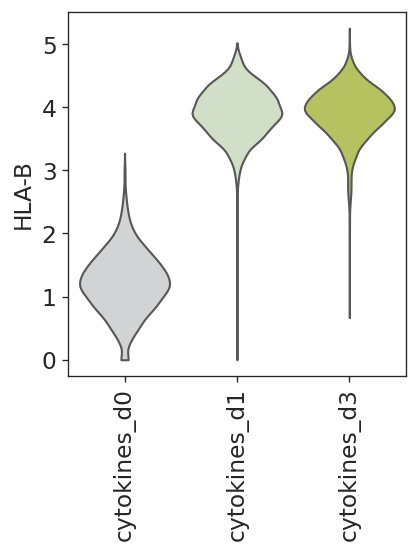

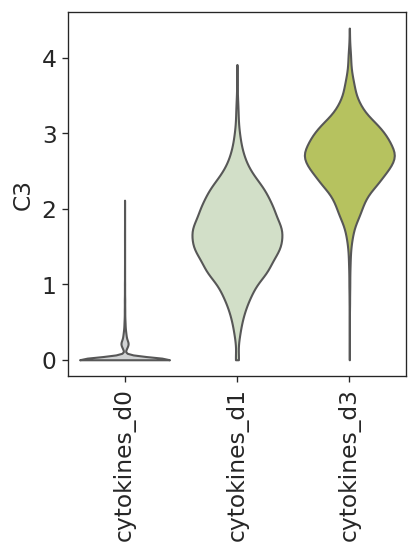

In [16]:
with sns.axes_style('ticks'):
    sc.pl.violin(adata, "CXCL6", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_CXCL6.pdf')
    
    sc.pl.violin(adata, "IL1A", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_IL1A.pdf')
    
    sc.pl.violin(adata, "IL11", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_IL11.pdf')
    sc.pl.violin(adata, "CD14", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_VCAM1.pdf')
    sc.pl.violin(adata, "VCAM1", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_VCAM1.pdf')
    sc.pl.violin(adata, "FAP", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_FAP.pdf')
    sc.pl.violin(adata, "GFAP", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_GFAP.pdf')
    sc.pl.violin(adata, "CLU", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_CLU.pdf')
    sc.pl.violin(adata, "B2M", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_B2M.pdf')
    sc.pl.violin(adata, "HLA-A", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_HLAA.pdf')
    sc.pl.violin(adata, "HLA-B", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_HLAB.pdf')
    sc.pl.violin(adata, "C3", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False,
                 save='_iAstrocytes_C3.pdf')
    

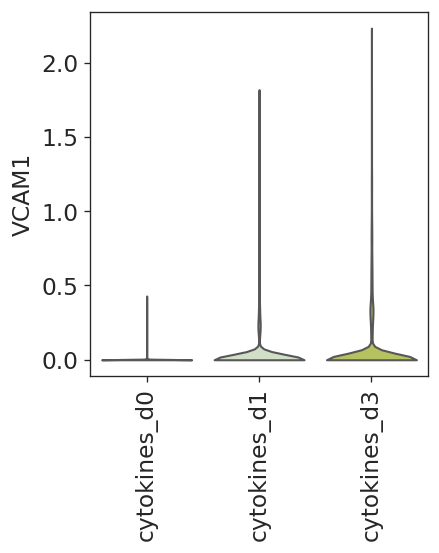

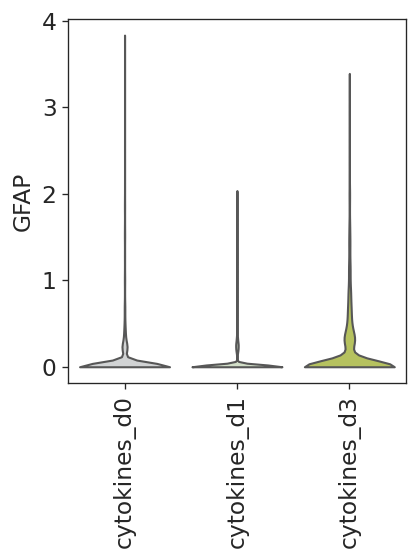

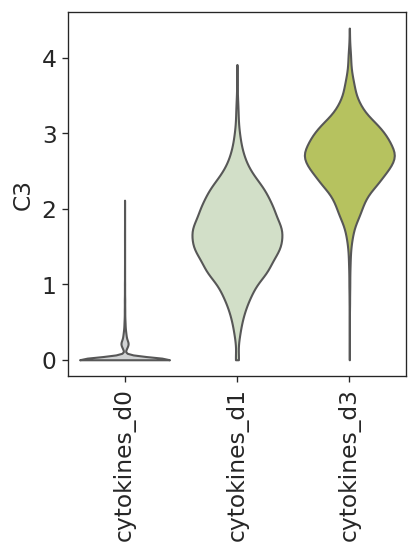

In [17]:
with sns.axes_style('ticks'):
    sc.pl.violin(adata, "VCAM1", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False)
    sc.pl.violin(adata, "GFAP", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False)
    sc.pl.violin(adata, "C3", groupby="Sample", rotation=90,
                 palette=['#d1d3d4','#d1e3c4','#c3d24f'],stripplot=False)